# Final pipeline

Everything that led from the four required detector families to the final submissions: a summary of all models, the data strategies and the inference strategies measured one at a time on the reference RT-DETRv2, the modelling experiments (family tuning, the final RT-DETRv2, YOLO26m-P2, the ensembles), a table that separates the three kinds of effect, 3-fold cross-validation of the final RT-DETRv2 recipe, how val relates to the public leaderboard, the final selection, and the commands that reproduce it. All numbers come from `experiments/results.csv` or from the shared evaluator on the saved val predictions of those runs (CPU only, no GPU). Plans and decisions in order: `docs/pipeline.md`.

| # | Section |
| --- | --- |
| 1 | [Setup](#1-setup) |
| 2 | [Summary of all models](#2-summary-of-all-models) |
| 3 | [Data strategies](#3-data-strategies) |
| 4 | [Inference strategies](#4-inference-strategies) |
| 5 | [Modelling](#5-modelling) |
| 6 | [Separating the effects](#6-separating-the-effects) |
| 7 | [Cross-validation](#7-cross-validation) |
| 8 | [Validation and the public leaderboard](#8-validation-and-the-public-leaderboard) |
| 9 | [Final selection](#9-final-selection) |
| 10 | [Reproduction](#10-reproduction) |
| 11 | [Conclusions](#11-conclusions) |

## 1. Setup

Imports, data root from `DATA_ROOT`, the annotations of the adopted split, and `experiments/results.csv`. Rules used throughout:

- **Reference model:** `rtdetr-baseline` (RT-DETRv2 R50, COCO weights, frame step 5, 7 epochs), the best family baseline.
- **Seed noise:** two seeds of the same RT-DETRv2 recipe differ by 0.0094 mAP (`rtdetr-lr_scaled` against `rtdetr-lr_scaled_repeat-s7`, `05_query_based.ipynb` §5). A training change counts only above that, or when it repeats with another seed.
- **Machines:** all runs trained on the PC (RTX 5070, 12 GB) except `rtdetr-recipe_step2_b16`, `yolo-yolo26m_p2_tiles_b16`, and `yolo-yolo26m_p2_tiles_b16_step2`, which trained on a Colab G4 (96 GB; `machine` colab in `results.csv`). Their GPU hours are not comparable with PC hours; their inference times were measured on the PC like all others.
- **Val halves:** settings chosen on the saved predictions are also scored on two disjoint halves of the 7 val clips (A: `uav0000086`, `uav0000137`, `uav0000263`, `uav0000339`; B: `uav0000117`, `uav0000182`, `uav0000305`), as in `docs/pipeline.md`. A post-processing gain counts when it holds on both halves.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns
from decouple import AutoConfig
from IPython.display import display

# make the repository root importable when the kernel starts in notebooks/
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))
# decouple locates .env from the caller file, which is a temp file inside a kernel
config = AutoConfig(search_path=PROJECT_ROOT)

from src.data.annotations import (
    AnnotationTables,
    load_annotations,
    load_clip_split,
    load_split_clips,
    load_test_images,
)
from src.data.classes import CLASS_NAMES
from src.evaluate import DATA_CONFIG_PATH, METRICS_FILE, PREDICTIONS_FILE, RESULTS_PATH, find_run_dir
from src.evaluation.coco_metrics import evaluate_frame_groups
from src.postprocess import evaluate_postprocess_settings
from src.training.experiment import load_experiment_config, merge_config
from src.visualization.plots import plot_grouped_bars, plot_training_history
from src.visualization.style import FAMILY_COLORS, SIZE_BUCKET_COLORS, set_plot_theme
from src.visualization.tables import load_run_histories

set_plot_theme()
pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(70)
DATA_ROOT = Path(config("DATA_ROOT"))
tables = load_annotations(DATA_ROOT, load_split_clips(DATA_CONFIG_PATH))
val_images = tables.images.filter(pl.col("split") == "val")
results = pl.read_csv(RESULTS_PATH).with_columns(family=pl.col("experiment").str.split("-").list.first())
pl.DataFrame({"results rows": [results.height], "val frames": [val_images.height], "val clips": [val_images["clip"].n_unique()]})

results rows,val frames,val clips
i64,i64,i64
77,2593,7


In [2]:
REFERENCE = "rtdetr-baseline"
SINGLE = "rtdetr-infer_recipe_step2_det500"  # best single model on val: M1 with 500 detections
YOLO26 = "yolo-yolo26m_p2_tiles_b16"  # YOLO26m-P2 on tiles, best single model on the LB
HEDGE = "postprocess-ens_recipe_frcnn_yolo_yolo1280_smooth"  # ensemble B
PREVIOUS = "postprocess-ens_rtdetr4_frcnn2_yolo2_smooth"  # ensemble D, second final submission
ENS_E = "postprocess-ens_rtdetr4_frcnn2_yolo3_smooth"  # ensemble E, D + YOLO26m-P2
FINAL = "postprocess-ens_rtdetr4_frcnn2_yolo4_smooth"  # ensemble F, E + its 2304 px pass (final)
FINAL_TRAINVAL = "postprocess-ens_trainval_rtdetr4_frcnn2_yolo2_smooth"  # ensemble D', trained on train and val
SEED_NOISE = 0.0094
METRICS = ["map", "map50", "map75", "ap_small", "ap_medium", "ap_large", "map_max_width_1920"]
DELTA_METRICS = ["map", "ap_small", "map_max_width_1920"]
FOLD_A = ["uav0000086", "uav0000137", "uav0000263", "uav0000339"]
clip_halves = {clip: "a" if clip[:10] in FOLD_A else "b" for clip in val_images["clip"].unique().to_list()}
final_config = load_experiment_config(PROJECT_ROOT / "config/postprocess/ens_rtdetr4_frcnn2_yolo4_smooth.toml")
previous_config = load_experiment_config(PROJECT_ROOT / "config/postprocess/ens_rtdetr4_frcnn2_yolo2_smooth.toml")
hedge_config = load_experiment_config(PROJECT_ROOT / "config/postprocess/ens_recipe_frcnn_yolo_yolo1280_smooth.toml")
trainval_config = load_experiment_config(PROJECT_ROOT / "config/postprocess/ens_trainval_rtdetr4_frcnn2_yolo2_smooth.toml")
predictions_cache: dict[str, pl.DataFrame] = {}


def run_dir_of(experiment: str) -> Path:
    return PROJECT_ROOT / find_run_dir(RESULTS_PATH, experiment)


def load_val_predictions(experiment: str) -> pl.DataFrame:
    if experiment not in predictions_cache:
        predictions_cache[experiment] = pl.read_parquet(run_dir_of(experiment) / PREDICTIONS_FILE)
    return predictions_cache[experiment]


def load_metrics(experiment: str) -> dict:
    return json.loads((run_dir_of(experiment) / METRICS_FILE).read_text())


def score_members(
    members: list[str], settings: dict[str, dict], split_tables: AnnotationTables, clip_groups: dict[str, str]
) -> pl.DataFrame:
    # fuse the saved val predictions of the members with the settings of D and F, one row per override
    base = merge_config(
        final_config,
        {"members": members, "weights": [1.0] * len(members), "fusion": "wbf" if len(members) > 1 else "none"},
    )
    member_predictions = [load_val_predictions(m) for m in members]
    table = evaluate_postprocess_settings(split_tables, member_predictions, base, list(settings.values()), clip_groups)
    return table.with_columns(setting=pl.Series(list(settings)))


def compare_runs(runs: dict[str, tuple[str, str]]) -> pl.DataFrame:
    # one row per run with its change, its reference run, and the differences from it
    plan = pl.DataFrame(
        [{"experiment": e, "change": change, "reference": ref} for e, (change, ref) in runs.items()]
    ).with_row_index("order")
    reference = results.select(
        pl.col("experiment").alias("reference"), *(pl.col(m).alias(f"reference_{m}") for m in DELTA_METRICS)
    )
    delta = pl.col("delta_map")
    return (
        plan.join(results.select("experiment", *DELTA_METRICS, "ms_per_image", "gpu_hours"), on="experiment")
        .join(reference, on="reference")
        .sort("order")
        .with_columns((pl.col(m) - pl.col(f"reference_{m}")).round(4).alias(f"delta_{m}") for m in DELTA_METRICS)
        .with_columns(
            verdict=pl.when(delta > SEED_NOISE).then(pl.lit("gain above noise"))
            .when(delta < -SEED_NOISE).then(pl.lit("loss above noise"))
            .otherwise(pl.lit("within noise"))
        )
        .select(
            "experiment", "change", "reference", *DELTA_METRICS,
            *(f"delta_{m}" for m in DELTA_METRICS), "verdict",
            pl.col("ms_per_image").round(1), pl.col("gpu_hours").round(2),
        )
    )

## 2. Summary of all models

The family baselines, the best tuning run of each family, the steps of the final pipeline, and the ensembles, among them the two final submissions F and D. Inference time is ms per image on the PC (RTX 5070) at the same input size and batch size 1; for an ensemble it is the sum of its members plus the fusion. GPU hours are training time; for an ensemble the sum of its members' training. The public LB column is filled for the runs that were submitted.

In [3]:
SUMMARY_RUNS = {
    "faster_rcnn-baseline": "two-stage anchor-based, baseline",
    "faster_rcnn-giou_loss": "two-stage anchor-based, tuned (GIoU loss, 5 epochs)",
    "retinanet-baseline": "one-stage anchor-based, baseline (best of its family)",
    "yolo-baseline": "one-stage anchor-free, baseline (tuning within 0.0004)",
    "rtdetr-baseline": "query-based, baseline (reference)",
    "rtdetr-augment_recipe": "reference + data: recipe augmentation (D1)",
    "rtdetr-recipe_step2": "M1: D1 + frames at step 2 (D2)",
    SINGLE: "M1 + 500 detections (I1), best single model",
    YOLO26: "one-stage anchor-free, YOLO26m-P2 on tiles (Colab, batch 16)",
    "postprocess-ens_yolo26m_p2_tiles_b16_tta": "YOLO26m-P2 TTA: WBF of 1920 px, 2304 px, flipped",
    "postprocess-temporal_smooth_rtdetr": "reference + temporal rescoring and smoothing (I6)",
    HEDGE: "ensemble B: 4 members, WBF + I6",
    PREVIOUS: "ensemble D: 8 members, WBF + I6 (second final submission)",
    ENS_E: "ensemble E: D + YOLO26m-P2",
    FINAL: "ensemble F: E + YOLO26m-P2 at 2304 px, 10 members (final)",
}
summary = (
    pl.DataFrame({"experiment": list(SUMMARY_RUNS), "role": list(SUMMARY_RUNS.values())})
    .with_row_index("order")
    .join(results, on="experiment")
    .sort("order")
    .select(
        "experiment", "role", pl.col(*METRICS).round(4), pl.col("ms_per_image").round(1),
        pl.col("gpu_hours").round(2), pl.col("public_lb").round(4),
    )
)
summary

experiment,role,map,map50,map75,ap_small,ap_medium,ap_large,map_max_width_1920,ms_per_image,gpu_hours,public_lb
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""faster_rcnn-baseline""","""two-stage anchor-based, baseline""",0.3013,0.6159,0.263,0.1069,0.2744,0.4635,0.2819,62.5,1.33,0.2273
"""faster_rcnn-giou_loss""","""two-stage anchor-based, tuned (GIoU loss, 5 epochs)""",0.3066,0.6258,0.265,0.1203,0.2924,0.4531,0.2902,60.8,0.67,null
"""retinanet-baseline""","""one-stage anchor-based, baseline (best of its family)""",0.2689,0.5116,0.2559,0.078,0.2347,0.4185,0.2631,48.6,1.38,0.1562
"""yolo-baseline""","""one-stage anchor-free, baseline (tuning within 0.0004)""",0.2671,0.5242,0.2443,0.1119,0.2483,0.396,0.2483,13.7,1.12,0.2097
"""rtdetr-baseline""","""query-based, baseline (reference)""",0.3209,0.6027,0.3056,0.1334,0.2719,0.4861,0.2935,53.2,1.43,0.2563
"""rtdetr-augment_recipe""","""reference + data: recipe augmentation (D1)""",0.3373,0.6297,0.3198,0.1449,0.3147,0.4988,0.3174,55.4,2.72,null
"""rtdetr-recipe_step2""","""M1: D1 + frames at step 2 (D2)""",0.3402,0.6233,0.3278,0.1396,0.3133,0.4989,0.3177,53.7,1.58,null
"""rtdetr-infer_recipe_step2_det500""","""M1 + 500 detections (I1), best single model""",0.3417,0.6264,0.329,0.1403,0.3148,0.5006,0.3191,53.9,1.58,0.2722
"""yolo-yolo26m_p2_tiles_b16""","""one-stage anchor-free, YOLO26m-P2 on tiles (Colab, batch 16)""",0.3064,0.5982,0.2855,0.1051,0.2771,0.4563,0.2751,40.9,0.96,0.2969


- **Best on val and on the LB:** ensemble F, 0.3905 val mAP and 0.3397 public LB, at 498 ms per image (the sum of its ten members).
- **Best single models:** `infer_recipe_step2_det500` on val (0.3417) and YOLO26m-P2 on the LB (0.2969 against 0.2722), although YOLO26m-P2 scores 0.035 lower on val.
- **Ensembles over single models:** every ensemble from B on is above every single model on val by at least 0.034; on the LB, F is 0.043 above the best single model and the YOLO26m-P2 TTA (three passes of one model) is 0.006 above it.

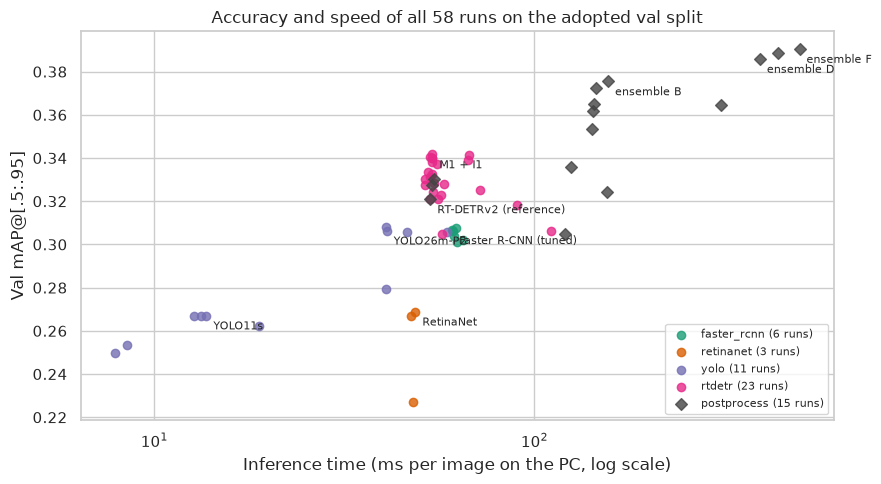

In [4]:
comparable = results.filter(~pl.col("experiment").str.contains("trainval|_fold|_half"))
LABELLED = {
    "faster_rcnn-giou_loss": "Faster R-CNN (tuned)",
    "retinanet-baseline": "RetinaNet",
    "yolo-baseline": "YOLO11s",
    "rtdetr-baseline": "RT-DETRv2 (reference)",
    SINGLE: "M1 + I1",
    YOLO26: "YOLO26m-P2",
    HEDGE: "ensemble B",
    PREVIOUS: "ensemble D",
    FINAL: "ensemble F",
}
fig, ax = plt.subplots(figsize=(9, 5))
for family, color in FAMILY_COLORS.items():
    rows = comparable.filter(pl.col("family") == family)
    ax.scatter(
        rows["ms_per_image"], rows["map"], color=color, s=36, alpha=0.8,
        marker="D" if family == "postprocess" else "o", label=f"{family} ({rows.height} runs)",
    )
for experiment, label in LABELLED.items():
    row = comparable.filter(pl.col("experiment") == experiment).row(0, named=True)
    ax.annotate(label, (row["ms_per_image"], row["map"]), xytext=(5, -10), textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set(
    xlabel="Inference time (ms per image on the PC, log scale)", ylabel="Val mAP@[.5:.95]",
    title=f"Accuracy and speed of all {comparable.height} runs on the adopted val split",
)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()

- **Three speed groups:** YOLO11s at 8 to 19 ms per image, the single torchvision and RT-DETRv2 models and YOLO26m-P2 at 40 to 110 ms, and the ensembles at 120 to 500 ms.
- **At about the same speed**, RT-DETRv2 (53 ms) is 0.02 to 0.04 mAP above Faster R-CNN (61 ms) and YOLO26m-P2 (41 ms).
- **The last steps are expensive:** D to F adds 0.0046 val mAP for 106 ms per image more (392 to 498 ms).

Per-class AP of the best model of each family, the best single model, and ensembles D and F. Bus and truck have 2 and few val clips, so their AP is the noisiest (`docs/pipeline.md` §2, observation 7).

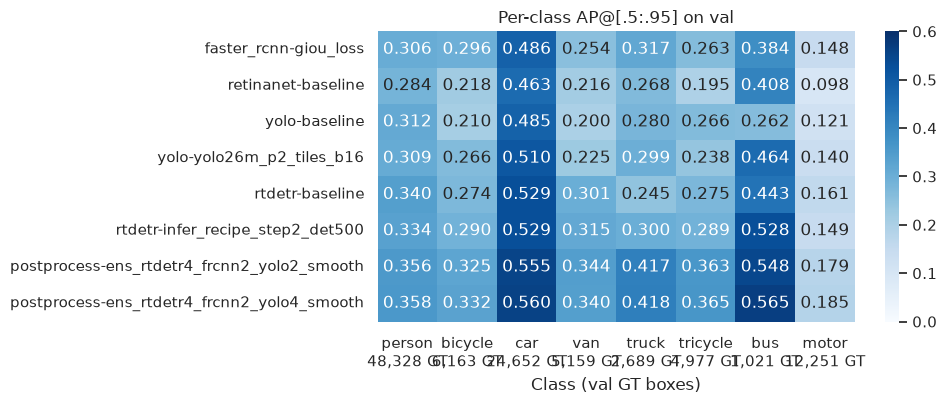

In [5]:
CLASS_RUNS = ["faster_rcnn-giou_loss", "retinanet-baseline", "yolo-baseline", YOLO26, REFERENCE, SINGLE, PREVIOUS, FINAL]
per_class = pl.DataFrame(
    [{"experiment": e} | load_metrics(e)["evaluation"]["per_class_ap"] for e in CLASS_RUNS]
).with_columns(pl.col(*CLASS_NAMES).round(3))
val_class_counts = tables.objects.filter(pl.col("split") == "val").group_by("class_id").len()
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.heatmap(
    per_class.select(CLASS_NAMES).to_numpy(), annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=0.6,
    xticklabels=[
        f"{name}\n{val_class_counts.filter(pl.col('class_id') == i)['len'].sum():,} GT"
        for i, name in enumerate(CLASS_NAMES)
    ],
    yticklabels=per_class["experiment"].to_list(), ax=ax,
)
ax.set(xlabel="Class (val GT boxes)", ylabel="", title="Per-class AP@[.5:.95] on val")
fig.tight_layout()

- **Car is the easiest class** for every model (0.46 to 0.56) and **motor the hardest** (0.10 to 0.19), with the second-highest share of small objects after person.
- **YOLO26m-P2 against YOLO11s:** bus 0.262 → 0.464, bicycle +0.056, van +0.025, car +0.025; tricycle −0.028, person about equal.
- **F against D:** bus +0.017, bicycle +0.007, motor +0.006, car +0.005, van −0.004. Bus has 2 val clips, so its AP is the noisiest.

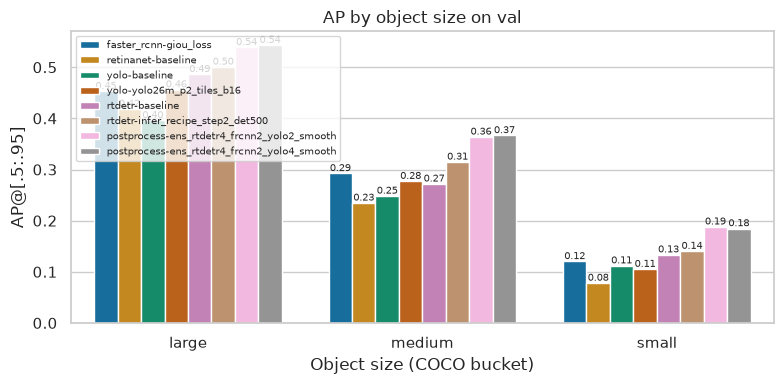

In [6]:
SIZE_RUNS = ["faster_rcnn-giou_loss", "retinanet-baseline", "yolo-baseline", YOLO26, REFERENCE, SINGLE, PREVIOUS, FINAL]
size_table = (
    results.filter(pl.col("experiment").is_in(SIZE_RUNS))
    .unpivot(["ap_small", "ap_medium", "ap_large"], index="experiment", variable_name="size", value_name="ap")
    .with_columns(
        pl.col("size").str.replace("ap_", ""),
        order=pl.col("experiment").replace_strict({e: i for i, e in enumerate(SIZE_RUNS)}),
    )
    .sort("order", "size")
)
fig = plot_grouped_bars(
    size_table, "size", "ap", "experiment",
    ("Object size (COCO bucket)", "AP@[.5:.95]", "AP by object size on val"), "{:.2f}",
)
fig.axes[0].legend(fontsize=7, loc="upper left")

- **Small objects stay the weak point:** AP_small is 0.08 to 0.19 for every model against 0.40 to 0.54 for large objects.
- **YOLO26m-P2 does not raise AP_small on val** (0.105 against 0.112 for YOLO11s) despite its stride 4 head; its gain over YOLO11s is in medium (+0.029) and large (+0.060) objects.
- **F against D:** large +0.004, medium +0.003, small −0.003.

## 3. Data strategies

Changes to the training data, one at a time on the reference RT-DETRv2 (frame step 5, 7 epochs, about 1.5 GPU hours each) unless the reference column says otherwise. All configs are in `config/rtdetr/` and `config/faster_rcnn/`; the code is `src/data/augment.py` and the `[augment]` and `[ignored_regions]` tables of the baselines.

- **D1 recipe augmentation** (`augment_recipe`): horizontal flip, photometric distortion, multi-scale training (shorter side 832 to 1216 px), and a clean last epoch, after the official RT-DETRv2 recipe ([dataloader config](https://github.com/lyuwenyu/RT-DETR/blob/main/rtdetrv2_pytorch/configs/rtdetrv2/include/dataloader.yml)). `augment_flip_photometric` is the same without multi-scale.
- **D2 frame step 2** (`step2`): 12,240 training frames instead of 4,919, 3 epochs in the same budget.
- **D3 ignored-region masking** (`mask_ignored`): ignored regions filled with the train mean colour, except inside labelled boxes.
- **Low-resolution augmentation** (`recipe_step2_low_res`): a quarter of the augmented frames shrunk 2×, on M1. Motivated by test frame sizes, a deviation from data rule 4 decided before the run (`docs/pipeline.md` §12.5).
- **D1 on Faster R-CNN** (`giou_recipe`): the same augmentation on the tuned Faster R-CNN member.
- **D2 on YOLO26m-P2** (`yolo26m_p2_tiles_b16_step2`): frames at step 2 for 8 epochs instead of step 5 for 20, the same number of tiles seen and warmup steps (section 5.1 describes the model). YOLO trains with the Ultralytics default augmentation throughout (mosaic, flip, HSV, translate, scale).
- **Train and val** (`trainval_*`): the final recipes trained on all 63 clips. Val is then seen in training, so these runs are checked only on the public LB (section 8).

In [7]:
DATA_RUNS = {
    "rtdetr-augment_flip_photometric": ("D1 without multi-scale", REFERENCE),
    "rtdetr-augment_recipe": ("D1 recipe augmentation", REFERENCE),
    "rtdetr-step2": ("D2 frames at step 2", REFERENCE),
    "rtdetr-mask_ignored": ("D3 ignored regions masked", REFERENCE),
    "rtdetr-recipe_step2": ("D1 + D2 (M1)", REFERENCE),
    "rtdetr-recipe_step2_repeat-s7": ("D1 + D2 (M1), seed 7", REFERENCE),
    "rtdetr-recipe_step2_low_res": ("low-resolution augmentation on M1", "rtdetr-recipe_step2"),
    "faster_rcnn-giou_recipe": ("D1 on the tuned Faster R-CNN", "faster_rcnn-giou_loss"),
    "yolo-yolo26m_p2_tiles_b16_step2": ("D2 frames at step 2 on YOLO26m-P2", YOLO26),
}
compare_runs(DATA_RUNS)

experiment,change,reference,map,ap_small,map_max_width_1920,delta_map,delta_ap_small,delta_map_max_width_1920,verdict,ms_per_image,gpu_hours
str,str,str,f64,f64,f64,f64,f64,f64,str,f64,f64
"""rtdetr-augment_flip_photometric""","""D1 without multi-scale""","""rtdetr-baseline""",0.3283,0.1259,0.3066,0.0074,-0.0075,0.0131,"""within noise""",54.4,1.49
"""rtdetr-augment_recipe""","""D1 recipe augmentation""","""rtdetr-baseline""",0.3373,0.1449,0.3174,0.0164,0.0115,0.0239,"""gain above noise""",55.4,2.72
"""rtdetr-step2""","""D2 frames at step 2""","""rtdetr-baseline""",0.3278,0.136,0.3045,0.0069,0.0026,0.011,"""within noise""",57.7,1.6
"""rtdetr-mask_ignored""","""D3 ignored regions masked""","""rtdetr-baseline""",0.3241,0.1459,0.2979,0.0032,0.0125,0.0044,"""within noise""",54.1,1.51
"""rtdetr-recipe_step2""","""D1 + D2 (M1)""","""rtdetr-baseline""",0.3402,0.1396,0.3177,0.0193,0.0062,0.0242,"""gain above noise""",53.7,1.58
"""rtdetr-recipe_step2_repeat-s7""","""D1 + D2 (M1), seed 7""","""rtdetr-baseline""",0.3404,0.1356,0.3127,0.0195,0.0022,0.0192,"""gain above noise""",53.1,1.54
"""rtdetr-recipe_step2_low_res""","""low-resolution augmentation on M1""","""rtdetr-recipe_step2""",0.3311,0.1404,0.3053,-0.0091,0.0008,-0.0124,"""within noise""",53.1,1.68
"""faster_rcnn-giou_recipe""","""D1 on the tuned Faster R-CNN""","""faster_rcnn-giou_loss""",0.3074,0.1179,0.2931,0.0008,-0.0024,0.0029,"""within noise""",62.0,0.57
"""yolo-yolo26m_p2_tiles_b16_step2""","""D2 frames at step 2 on YOLO26m-P2""","""yolo-yolo26m_p2_tiles_b16""",0.2796,0.0911,0.2502,-0.0268,-0.014,-0.0249,"""loss above noise""",40.8,0.93


- **D1 recipe augmentation** is the only single data change above the seed noise (+0.0164 mAP, +0.0115 AP_small); without multi-scale it gains +0.0074, within noise.
- **D2 frames at step 2** adds +0.0069 alone and brings D1 to +0.0193 (M1), repeated with seed 7 (+0.0195).
- **Within noise or lost:** ignored-region masking (+0.0032), low-resolution augmentation on M1 (−0.0091), D1 on Faster R-CNN (+0.0008).
- **D2 on YOLO26m-P2 loses** 0.0268, above the noise (section 5.1 shows the training curves).

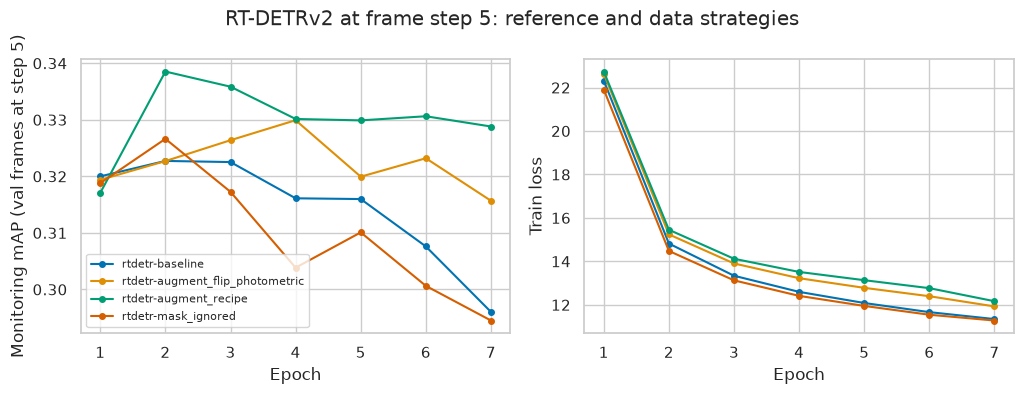

In [8]:
CURVE_RUNS = [REFERENCE, "rtdetr-augment_flip_photometric", "rtdetr-augment_recipe", "rtdetr-mask_ignored"]
histories = load_run_histories({e: run_dir_of(e) for e in CURVE_RUNS})
fig = plot_training_history(
    histories,
    {"val/map": "Monitoring mAP (val frames at step 5)", "train/loss": "Train loss"},
    "RT-DETRv2 at frame step 5: reference and data strategies",
)

- **Without augmentation, monitoring mAP peaks at epoch 2 to 3** and falls by 0.03 by epoch 7 (reference, masking), while the train loss keeps falling: overfitting to the 4,919 step 5 frames.
- **D1 keeps monitoring mAP within 0.01 of its epoch 2 peak** (0.338) to epoch 7, with a higher train loss throughout.

## 4. Inference strategies

Changes that need no training: each reuses the `best.pt` of its reference run with other inference settings (`config/<family>/infer_*.toml`, `src.predict --inference-config`), or post-processes its saved predictions (`config/postprocess/`, `src/postprocess.py`).

- **I1 500 detections**: RT-DETRv2 keeps up to 500 (query, class) pairs instead of 300, the LB limit.
- **I2 horizontal flip**: predictions on mirrored frames, alone and fused with the plain pass by WBF.
- **I3 inference size**: shorter side 1152, 1280, 1408 px instead of the training size 1024 px; for YOLO `imgsz` 1280 instead of 1824, and 2304 instead of 1920 for YOLO26m-P2.
- **NMS IoU 0.65** instead of 0.5 for YOLO26m-P2, for overlapping objects of one class.
- **YOLO26m-P2 TTA**: WBF (IoU 0.55, equal weights) of its 1920 px, 2304 px, and flipped passes.
- **I6 temporal rescoring and box smoothing** (bonus notebook `07_bonus_temporality.ipynb`): detections linked across consecutive frames, scores moved halfway toward the track maximum, boxes smoothed along the track.

In [9]:
INFERENCE_RUNS = {
    "rtdetr-infer_det500": ("I1 500 detections", REFERENCE),
    SINGLE: ("I1 500 detections", "rtdetr-recipe_step2"),
    "rtdetr-infer_hflip": ("I2 flipped frames alone", REFERENCE),
    "postprocess-ens_rtdetr_hflip": ("I2 flip TTA (WBF of both passes)", REFERENCE),
    "rtdetr-infer_recipe_hflip": ("I2 flipped frames alone, model trained with flips", "rtdetr-augment_recipe"),
    "yolo-infer_hflip": ("I2 flipped frames alone", "yolo-baseline"),
    "rtdetr-infer_size1152": ("I3 shorter side 1152 px", REFERENCE),
    "rtdetr-infer_size1280": ("I3 shorter side 1280 px", REFERENCE),
    "rtdetr-infer_size1408": ("I3 shorter side 1408 px", REFERENCE),
    "rtdetr-infer_recipe_size1152": ("I3 shorter side 1152 px", "rtdetr-augment_recipe"),
    "rtdetr-infer_recipe_step2_size1152": ("I3 shorter side 1152 px", "rtdetr-recipe_step2"),
    "yolo-infer_imgsz1280": ("I3 imgsz 1280 instead of 1824", "yolo-baseline"),
    "yolo-infer_yolo26m_p2_tiles_b16_hflip": ("I2 flipped frames alone", YOLO26),
    "yolo-infer_yolo26m_p2_tiles_b16_size2304": ("I3 imgsz 2304 instead of 1920", YOLO26),
    "yolo-infer_yolo26m_p2_tiles_b16_iou065": ("NMS IoU 0.65 instead of 0.5", YOLO26),
    "postprocess-ens_yolo26m_p2_tiles_b16_tta": ("TTA: WBF of 1920 px, 2304 px, flipped", YOLO26),
    "postprocess-temporal_rtdetr": ("I6 temporal rescoring", REFERENCE),
    "postprocess-temporal_smooth_rtdetr": ("I6 temporal rescoring + box smoothing", REFERENCE),
}
compare_runs(INFERENCE_RUNS)

experiment,change,reference,map,ap_small,map_max_width_1920,delta_map,delta_ap_small,delta_map_max_width_1920,verdict,ms_per_image,gpu_hours
str,str,str,f64,f64,f64,f64,f64,f64,str,f64,f64
"""rtdetr-infer_det500""","""I1 500 detections""","""rtdetr-baseline""",0.323,0.134,0.2954,0.0021,0.0006,0.0019,"""within noise""",56.6,1.43
"""rtdetr-infer_recipe_step2_det500""","""I1 500 detections""","""rtdetr-recipe_step2""",0.3417,0.1403,0.3191,0.0015,0.0007,0.0014,"""within noise""",53.9,1.58
"""rtdetr-infer_hflip""","""I2 flipped frames alone""","""rtdetr-baseline""",0.3049,0.1179,0.2737,-0.016,-0.0155,-0.0198,"""loss above noise""",57.0,1.43
"""postprocess-ens_rtdetr_hflip""","""I2 flip TTA (WBF of both passes)""","""rtdetr-baseline""",0.3049,0.1151,0.267,-0.016,-0.0183,-0.0265,"""loss above noise""",120.4,1.43
"""rtdetr-infer_recipe_hflip""","""I2 flipped frames alone, model trained with flips""","""rtdetr-augment_recipe""",0.3382,0.1394,0.319,0.0009,-0.0055,0.0016,"""within noise""",53.7,2.72
"""yolo-infer_hflip""","""I2 flipped frames alone""","""yolo-baseline""",0.2621,0.1105,0.2402,-0.005,-0.0014,-0.0081,"""within noise""",18.8,1.12
"""rtdetr-infer_size1152""","""I3 shorter side 1152 px""","""rtdetr-baseline""",0.3254,0.1475,0.2957,0.0045,0.0141,0.0022,"""within noise""",72.0,1.43
"""rtdetr-infer_size1280""","""I3 shorter side 1280 px""","""rtdetr-baseline""",0.3185,0.15,0.2906,-0.0024,0.0166,-0.0029,"""within noise""",90.0,1.43
"""rtdetr-infer_size1408""","""I3 shorter side 1408 px""","""rtdetr-baseline""",0.3062,0.158,0.281,-0.0147,0.0246,-0.0125,"""loss above noise""",110.9,1.43


- **500 detections (I1)** add +0.0015 to +0.0021, within noise; kept because they cost nothing.
- **Flipped frames** lose 0.016 on a model trained without flips and match the plain pass (+0.0009) on a model trained with flips.
- **Larger inference sizes trade mAP for AP_small:** on RT-DETRv2 1152 px gives +0.0045 mAP and +0.014 AP_small, 1408 px −0.0147 mAP and +0.025 AP_small; on YOLO26m-P2 2304 px gives −0.0006 mAP and +0.009 AP_small.
- **YOLO26m-P2 TTA** (WBF of 1920 px, 2304 px, and flipped passes) is the only inference change above the noise: +0.018 mAP, +0.016 AP_small, at 3.8 times the inference time. No single pass gains alone (−0.0006 to +0.0016).
- **Temporal rescoring and smoothing (I6)** add +0.0092, just within noise, but on both val halves and on the LB (`07_bonus_temporality.ipynb`).

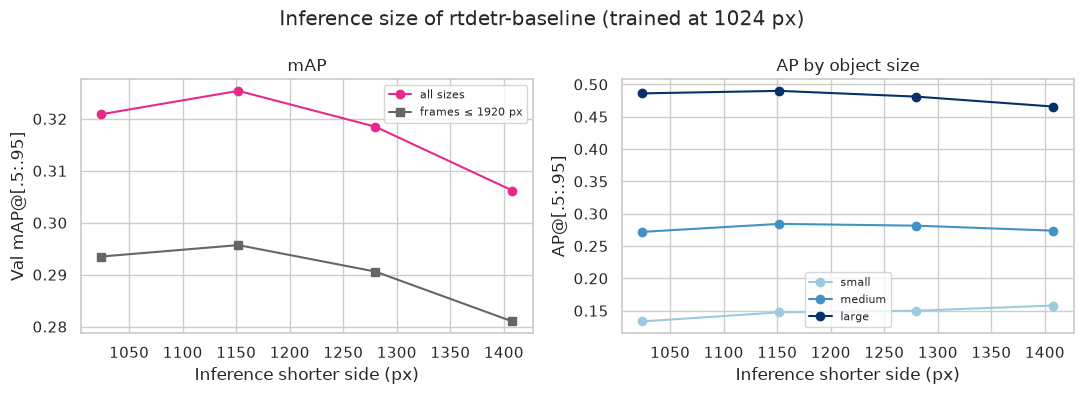

In [10]:
SIZE_SWEEP = {1024: REFERENCE, 1152: "rtdetr-infer_size1152", 1280: "rtdetr-infer_size1280", 1408: "rtdetr-infer_size1408"}
sweep = (
    pl.DataFrame({"shorter_side": list(SIZE_SWEEP), "experiment": list(SIZE_SWEEP.values())})
    .join(results, on="experiment")
    .sort("shorter_side")
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(sweep["shorter_side"], sweep["map"], marker="o", color=FAMILY_COLORS["rtdetr"], label="all sizes")
axes[0].plot(sweep["shorter_side"], sweep["map_max_width_1920"], marker="s", color="0.4", label="frames ≤ 1920 px")
axes[0].set(xlabel="Inference shorter side (px)", ylabel="Val mAP@[.5:.95]", title="mAP")
axes[0].legend(fontsize=8)
for size, color in SIZE_BUCKET_COLORS.items():
    axes[1].plot(sweep["shorter_side"], sweep[f"ap_{size}"], marker="o", color=color, label=size)
axes[1].set(xlabel="Inference shorter side (px)", ylabel="AP@[.5:.95]", title="AP by object size")
axes[1].legend(fontsize=8)
fig.suptitle("Inference size of rtdetr-baseline (trained at 1024 px)")
fig.tight_layout()

- **mAP peaks at 1152 px** (0.3254) and falls below the training size from 1280 px on; at 1408 px it is 0.015 lower.
- **AP_small rises with every size step** (0.133 to 0.158) while AP_large falls (0.486 to 0.466): larger inputs help small objects and hurt large ones, and the large and medium buckets dominate mAP.

## 5. Modelling

### 5.1 Family tuning, the final RT-DETRv2, and YOLO26m-P2

The tuning runs of the four required families against their baselines (details in notebooks 02 to 05), the weight EMA, and M1, the final single RT-DETRv2 (D1 and D2 combined, 3 epochs at step 2, best epoch 1), with its seed repeat.

Two runs used a Colab G4 (96 GB) that became available after the families were tuned:

- **YOLO26m-P2** (`yolo26m_p2_tiles_b16`): one combined change against `yolo-baseline`, not one factor. YOLO26m instead of YOLO11s ([Ultralytics YOLO26](https://docs.ultralytics.com/models/yolo26/)); a P2 head with stride 4 (`yolo26-p2.yaml`; P3 to P5 weights from `yolo26m.pt`, the new layers random); training on 1088 px tiles of frames resized to 1920 px wide (`src/data/yolo_export.py`), so objects keep the scale of full-frame inference at `imgsz` 1920; SGD with LR 0.01, cosine decay, 1 warmup epoch; mosaic off for the last 5 of 20 epochs; batch 16 with the Ultralytics effective batch 64. Notebook `04_anchor_free.ipynb` predates it. The same recipe at batch 3 on the PC did not complete.
- **M1 at effective batch 16** (`recipe_step2_b16`): batch 8 with gradient accumulation 2 instead of 4, the batch size for which the official RT-DETRv2 LR was set; 6 epochs, warmup over the same 8,000 frames.

In [11]:
TUNING_RUNS = {
    "faster_rcnn-lr_cosine": ("cosine LR schedule", "faster_rcnn-baseline"),
    "faster_rcnn-anchors_small": ("anchor sizes 16 to 256", "faster_rcnn-baseline"),
    "faster_rcnn-giou_loss": ("GIoU box loss, 5 epochs", "faster_rcnn-baseline"),
    "faster_rcnn-baseline_5ep-s7": ("5 epochs, seed 7 (noise check)", "faster_rcnn-baseline"),
    "retinanet-focal_loss": ("focal loss gamma 1", "retinanet-baseline"),
    "retinanet-anchors_eda": ("anchors from the box statistics", "retinanet-baseline"),
    "yolo-tal_topk": ("TAL top-k", "yolo-baseline"),
    "yolo-scale_025": ("scale augmentation 0.25", "yolo-baseline"),
    "yolo-imgsz_1280": ("imgsz 1280", "yolo-baseline"),
    "rtdetr-lr_scaled": ("LR scaled to batch 4", REFERENCE),
    "rtdetr-lr_scaled_repeat-s7": ("LR scaled, seed 7", REFERENCE),
    "rtdetr-denoising_groups": ("200 denoising queries", REFERENCE),
    "rtdetr-ema": ("weight EMA", REFERENCE),
    "rtdetr-recipe_step2": ("M1: D1 + D2", REFERENCE),
    "rtdetr-recipe_step2_repeat-s7": ("M1, seed 7", REFERENCE),
    "rtdetr-recipe_step2_b16": ("M1 at effective batch 16 (Colab)", "rtdetr-recipe_step2"),
    YOLO26: ("YOLO26m-P2 on tiles, SGD cosine, batch 16 (Colab)", "yolo-baseline"),
}
compare_runs(TUNING_RUNS)

experiment,change,reference,map,ap_small,map_max_width_1920,delta_map,delta_ap_small,delta_map_max_width_1920,verdict,ms_per_image,gpu_hours
str,str,str,f64,f64,f64,f64,f64,f64,str,f64,f64
"""faster_rcnn-lr_cosine""","""cosine LR schedule""","""faster_rcnn-baseline""",0.3062,0.1225,0.2878,0.0049,0.0156,0.0059,"""within noise""",60.9,1.3
"""faster_rcnn-anchors_small""","""anchor sizes 16 to 256""","""faster_rcnn-baseline""",0.3037,0.1107,0.2867,0.0024,0.0038,0.0048,"""within noise""",61.5,0.65
"""faster_rcnn-giou_loss""","""GIoU box loss, 5 epochs""","""faster_rcnn-baseline""",0.3066,0.1203,0.2902,0.0053,0.0134,0.0083,"""within noise""",60.8,0.67
"""faster_rcnn-baseline_5ep-s7""","""5 epochs, seed 7 (noise check)""","""faster_rcnn-baseline""",0.3022,0.1161,0.2806,0.0009,0.0092,-0.0013,"""within noise""",64.8,0.69
"""retinanet-focal_loss""","""focal loss gamma 1""","""retinanet-baseline""",0.2671,0.0807,0.2609,-0.0018,0.0027,-0.0022,"""within noise""",47.3,0.58
"""retinanet-anchors_eda""","""anchors from the box statistics""","""retinanet-baseline""",0.2271,0.0766,0.2247,-0.0418,-0.0014,-0.0384,"""loss above noise""",48.0,0.7
"""yolo-tal_topk""","""TAL top-k""","""yolo-baseline""",0.2671,0.1146,0.2417,0.0,0.0027,-0.0066,"""within noise""",13.3,1.08
"""yolo-scale_025""","""scale augmentation 0.25""","""yolo-baseline""",0.2667,0.1094,0.2581,-0.0004,-0.0025,0.0098,"""within noise""",12.7,1.02
"""yolo-imgsz_1280""","""imgsz 1280""","""yolo-baseline""",0.2498,0.1119,0.2411,-0.0173,0.0,-0.0072,"""loss above noise""",7.9,1.05


- **Faster R-CNN tuning** stays within noise (+0.0024 to +0.0053); its 5 epoch seed repeat of the baseline (+0.0009) sets the scale.
- **RetinaNet anchors from the box statistics** lose 0.042; **YOLO11s at 1280 px** loses 0.017.
- **RT-DETRv2:** the scaled LR gain (+0.0096) did not repeat with seed 7 (+0.0002); weight EMA gains +0.0115 with one seed; M1 gains +0.0193 and +0.0195 with two seeds. Effective batch 16 on the G4 changes M1 by −0.0004.
- **YOLO26m-P2** is the largest single training gain in the project, +0.0393 over YOLO11s, as one combined change of model, head, tiles, and optimizer, so the parts are not separated; AP_small falls by 0.007.

Per-epoch monitoring of the two YOLO26m-P2 runs (Ultralytics validation on val tiles at step 5 with the one-to-one head, so the absolute values differ from the shared evaluator; `best.pt` is the epoch with the highest monitoring mAP). The x axis is the share of the training run, because both runs see about the same number of tiles in 20 and 8 epochs.

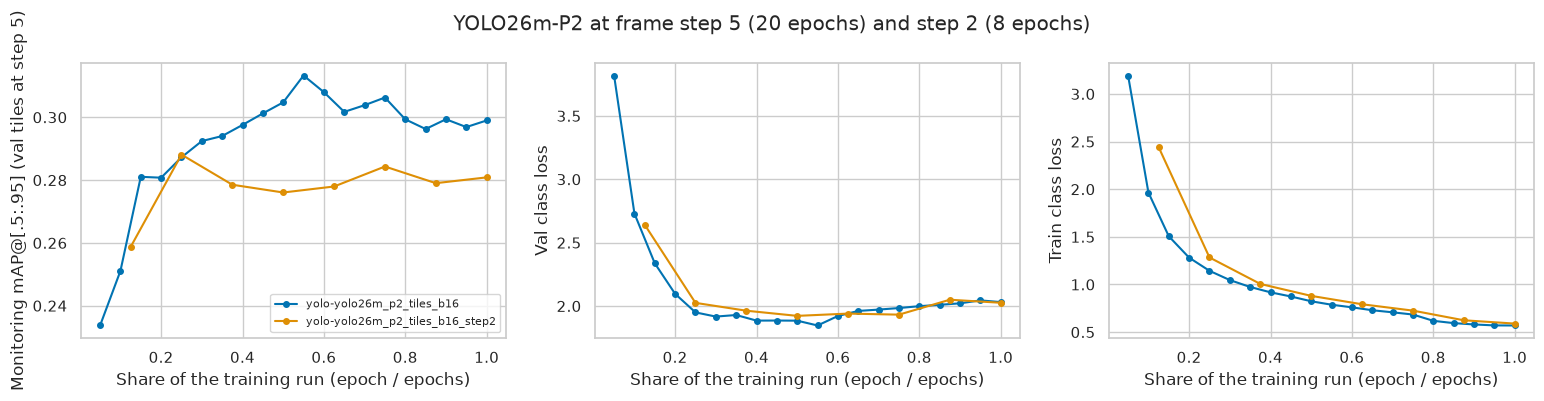

In [12]:
YOLO26_RUNS = [YOLO26, "yolo-yolo26m_p2_tiles_b16_step2"]
yolo26_histories = load_run_histories({e: run_dir_of(e) for e in YOLO26_RUNS}).with_columns(
    training_share=pl.col("epoch") / pl.col("epoch").max().over("experiment")
)
fig = plot_training_history(
    yolo26_histories,
    {"metrics/mAP50-95(B)": "Monitoring mAP@[.5:.95] (val tiles at step 5)", "val/cls_loss": "Val class loss", "train/cls_loss": "Train class loss"},
    "YOLO26m-P2 at frame step 5 (20 epochs) and step 2 (8 epochs)",
    x="training_share",
    xlabel="Share of the training run (epoch / epochs)",
)

- **Step 5 (20 epochs):** monitoring mAP peaks at epoch 11 (0.313, `best.pt`) and ends at 0.299; the val class loss is lowest at about the same point and rises afterwards while the train class loss keeps falling, so the model overfits from about the middle of training.
- **Step 2 (8 epochs):** both runs are equal up to a quarter of training (0.288); step 2 then stays between 0.276 and 0.284 while step 5 keeps improving to 0.313.
- Hypothesis, not tested: frames 2 apart are near duplicates (median IoU 0.81 between them, `01_eda.ipynb` section 9), so step 2 adds few new objects, while each step 5 frame is seen 20 instead of 8 times.

### 5.2 Ensembles

Weighted Boxes Fusion ([Solovyev et al., 2021](https://arxiv.org/abs/1910.13302); `src/inference/fusion.py`) of the saved predictions of several runs: boxes of all members are clustered per class at IoU 0.65 and each cluster becomes one box with the score-weighted mean coordinates and the mean score over all members. The ensemble runs in `results.csv`, in the order they were built (R `rtdetr-baseline`, F `faster_rcnn-giou_loss`, Y `yolo-baseline`), each against the run it extends; E and F add the YOLO26m-P2 members to D:

In [13]:
ENSEMBLE_RUNS = {
    "postprocess-ens_rtdetr_frcnn": ("WBF R + F", REFERENCE),
    "postprocess-ens_rtdetr_frcnn_yolo": ("WBF R + F + Y", "postprocess-ens_rtdetr_frcnn"),
    "postprocess-ens_all_runs": ("4 RT-DETRv2 runs at half weight + F + Y", "postprocess-ens_rtdetr_frcnn_yolo"),
    "postprocess-ens_rtdetr_frcnn_yolo_temporal": ("R + F + Y, then I6 rescoring", "postprocess-ens_rtdetr_frcnn_yolo"),
    "postprocess-ens_rtdetr_frcnn_yolo_temporal_smooth": ("+ box smoothing", "postprocess-ens_rtdetr_frcnn_yolo_temporal"),
    "postprocess-ens_recipe_frcnn_yolo_smooth": ("R replaced by augment_recipe (D1)", "postprocess-ens_rtdetr_frcnn_yolo_temporal_smooth"),
    HEDGE: ("+ yolo-imgsz_1280 (B)", "postprocess-ens_recipe_frcnn_yolo_smooth"),
    PREVIOUS: ("+ 3 RT-DETRv2 members and faster_rcnn-lr_cosine (D)", HEDGE),
    ENS_E: ("+ yolo-yolo26m_p2_tiles_b16 (E)", PREVIOUS),
    FINAL: ("+ its 2304 px pass (F)", ENS_E),
}
compare_runs(ENSEMBLE_RUNS)

experiment,change,reference,map,ap_small,map_max_width_1920,delta_map,delta_ap_small,delta_map_max_width_1920,verdict,ms_per_image,gpu_hours
str,str,str,f64,f64,f64,f64,f64,f64,str,f64,f64
"""postprocess-ens_rtdetr_frcnn""","""WBF R + F""","""rtdetr-baseline""",0.336,0.1382,0.3107,0.0151,0.0048,0.0172,"""gain above noise""",124.6,2.1
"""postprocess-ens_rtdetr_frcnn_yolo""","""WBF R + F + Y""","""postprocess-ens_rtdetr_frcnn""",0.3533,0.1518,0.3307,0.0173,0.0136,0.02,"""gain above noise""",141.7,3.22
"""postprocess-ens_all_runs""","""4 RT-DETRv2 runs at half weight + F + Y""","""postprocess-ens_rtdetr_frcnn_yolo""",0.3645,0.1607,0.34,0.0112,0.0089,0.0093,"""gain above noise""",309.7,7.7
"""postprocess-ens_rtdetr_frcnn_yolo_temporal""","""R + F + Y, then I6 rescoring""","""postprocess-ens_rtdetr_frcnn_yolo""",0.3617,0.1616,0.3408,0.0084,0.0098,0.0101,"""within noise""",142.4,3.22
"""postprocess-ens_rtdetr_frcnn_yolo_temporal_smooth""","""+ box smoothing""","""postprocess-ens_rtdetr_frcnn_yolo_temporal""",0.3649,0.1634,0.3434,0.0032,0.0018,0.0026,"""within noise""",143.2,3.22
"""postprocess-ens_recipe_frcnn_yolo_smooth""","""R replaced by augment_recipe (D1)""","""postprocess-ens_rtdetr_frcnn_yolo_temporal_smooth""",0.3724,0.1741,0.3513,0.0075,0.0107,0.0079,"""within noise""",145.3,4.52
"""postprocess-ens_recipe_frcnn_yolo_yolo1280_smooth""","""+ yolo-imgsz_1280 (B)""","""postprocess-ens_recipe_frcnn_yolo_smooth""",0.3755,0.1772,0.3559,0.0031,0.0031,0.0046,"""within noise""",156.2,5.57
"""postprocess-ens_rtdetr4_frcnn2_yolo2_smooth""","""+ 3 RT-DETRv2 members and faster_rcnn-lr_cosine (D)""","""postprocess-ens_recipe_frcnn_yolo_yolo1280_smooth""",0.3859,0.188,0.3611,0.0104,0.0108,0.0052,"""gain above noise""",391.9,9.98
"""postprocess-ens_rtdetr4_frcnn2_yolo3_smooth""","""+ yolo-yolo26m_p2_tiles_b16 (E)""","""postprocess-ens_rtdetr4_frcnn2_yolo2_smooth""",0.3887,0.1878,0.362,0.0028,-0.0002,0.0009,"""within noise""",437.9,10.95


- **Fusion of the families gives the large steps:** WBF of RT-DETRv2 and Faster R-CNN +0.0151, adding YOLO11s +0.0173, and D's additional RT-DETRv2 and Faster R-CNN members +0.0104.
- **E and F** add +0.0028 and +0.0018 mAP, within the noise, and 46 and 60 ms per image.
- **GPU hours** of F equal those of E: the 2304 px member reuses the YOLO26m-P2 checkpoint.

Forward selection from B to D and on to F, recomputed here on the saved val predictions with the settings of D and F (WBF IoU 0.65, equal weights, I6). Each step adds the member that raised val mAP most in the grids of `docs/pipeline.md` §12.2 and §13; the last row is the keep check of `faster_rcnn-giou_recipe` (section 3), which replaces `faster_rcnn-giou_loss` in F. Members were chosen on all of val, so the halves are the check.

In [14]:
b_members = list(hedge_config["members"])
d_members = list(previous_config["members"])
f_members = list(final_config["members"])
SELECTION_STEPS = {
    "B": b_members,
    "B + infer_recipe_step2_det500": b_members + [SINGLE],
    "+ recipe_step2_repeat-s7": b_members + [SINGLE, "rtdetr-recipe_step2_repeat-s7"],
    "+ infer_recipe_hflip (C)": b_members + [SINGLE, "rtdetr-recipe_step2_repeat-s7", "rtdetr-infer_recipe_hflip"],
    "+ faster_rcnn-lr_cosine (D)": d_members,
    "+ yolo26m_p2_tiles_b16 (E)": d_members + [YOLO26],
    "+ infer_yolo26m_p2_tiles_b16_size2304 (F)": f_members,
    "F with giou_recipe instead of giou_loss": [
        "faster_rcnn-giou_recipe" if m == "faster_rcnn-giou_loss" else m for m in f_members
    ],
}
selection = pl.concat(
    [score_members(members, {name: {}}, tables, clip_halves) for name, members in SELECTION_STEPS.items()]
)
selection.select(
    "setting", pl.col("map", "map_a", "map_b", "ap_small", "map_max_width_1920").round(4),
    *(pl.col(c).diff().round(4).alias(f"delta_{c}") for c in ("map", "map_a", "map_b")),
)

setting,map,map_a,map_b,ap_small,map_max_width_1920,delta_map,delta_map_a,delta_map_b
str,f64,f64,f64,f64,f64,f64,f64,f64
"""B""",0.3755,0.3769,0.314,0.1772,0.3559,null,null,null
"""B + infer_recipe_step2_det500""",0.3813,0.3821,0.3189,0.1857,0.3608,0.0058,0.0052,0.0049
"""+ recipe_step2_repeat-s7""",0.3824,0.3853,0.3179,0.1853,0.359,0.0011,0.0032,-0.0011
"""+ infer_recipe_hflip (C)""",0.3829,0.3864,0.3208,0.1891,0.3584,0.0004,0.0011,0.0029
"""+ faster_rcnn-lr_cosine (D)""",0.3859,0.3882,0.3215,0.188,0.3611,0.0031,0.0017,0.0007
"""+ yolo26m_p2_tiles_b16 (E)""",0.3887,0.3896,0.3272,0.1878,0.362,0.0027,0.0014,0.0057
"""+ infer_yolo26m_p2_tiles_b16_size2304 (F)""",0.3905,0.3911,0.3291,0.1846,0.3632,0.0019,0.0015,0.0019
"""F with giou_recipe instead of giou_loss""",0.3892,0.39,0.3265,0.1879,0.3611,-0.0013,-0.0011,-0.0026


- **Every step from B to F raises mAP and both val halves,** except the seed 7 member (half B −0.0011).
- **Adding YOLO26m-P2 (E)** gives the largest gain on half B of the late steps (+0.0057).
- **`giou_recipe` in place of `giou_loss`** lowers F on both halves (−0.0013 mAP), so `giou_loss` stays.

Family ablation of F: each detector family removed from the ten members, with the settings of F. Without YOLO26m-P2 the members are those of D. Removals of single members and further candidate members (laptop grid, `docs/pipeline.md` §13) changed val mAP by at most 0.002.

In [15]:
FAMILY_PREFIXES = {
    "RT-DETRv2 (4 members)": ("rtdetr-",),
    "Faster R-CNN (2 members)": ("faster_rcnn-",),
    "YOLO11s (2 members)": ("yolo-baseline", "yolo-imgsz_1280"),
    "YOLO26m-P2 (2 members, = D)": ("yolo-yolo26m", "yolo-infer_yolo26m"),
}
f_row = selection.filter(pl.col("setting") == "+ infer_yolo26m_p2_tiles_b16_size2304 (F)").with_columns(setting=pl.lit("F"))
ablation = pl.concat(
    [f_row]
    + [
        score_members([m for m in f_members if not m.startswith(prefixes)], {f"F without {family}": {}}, tables, clip_halves)
        for family, prefixes in FAMILY_PREFIXES.items()
    ]
)
ablation.select(
    "setting", pl.col("map", "map_a", "map_b", "ap_small", "map_max_width_1920").round(4),
    *((pl.col(c) - pl.col(c).first()).round(4).alias(f"delta_{c}") for c in ("map", "map_a", "map_b")),
)

setting,map,map_a,map_b,ap_small,map_max_width_1920,delta_map,delta_map_a,delta_map_b
str,f64,f64,f64,f64,f64,f64,f64,f64
"""F""",0.3905,0.3911,0.3291,0.1846,0.3632,0.0,0.0,0.0
"""F without RT-DETRv2 (4 members)""",0.3718,0.3739,0.3079,0.1688,0.3478,-0.0188,-0.0171,-0.0211
"""F without Faster R-CNN (2 members)""",0.3864,0.3869,0.325,0.1812,0.3584,-0.0042,-0.0042,-0.0041
"""F without YOLO11s (2 members)""",0.3863,0.3877,0.327,0.1801,0.3576,-0.0043,-0.0034,-0.0021
"""F without YOLO26m-P2 (2 members, = D)""",0.3859,0.3882,0.3215,0.188,0.3611,-0.0046,-0.0029,-0.0076


- **RT-DETRv2 carries the ensemble:** removing its four members costs 0.0188 mAP, about twice the seed noise, on both halves.
- **Each other family adds 0.004 to 0.005** on both halves: Faster R-CNN 0.0042, YOLO11s 0.0043, YOLO26m-P2 0.0046 (half B 0.0076). YOLO11s still adds after YOLO26m-P2 joins.

## 6. Separating the effects

The path from the reference to F, one kind of change per step, all scored here on the same val frames and halves: data (training frames and augmentation), inference (500 detections, temporal rescoring and smoothing), and modelling (the ensemble of the four families). The 2 × 2 table then crosses the model (single or ensemble) with the temporal step, to show whether the inference gain depends on the model.

In [16]:
NO_TEMPORAL = {"temporal": {"enabled": False}}
path_rows = pl.concat(
    [
        score_members([REFERENCE], {"reference (rtdetr-baseline)": NO_TEMPORAL}, tables, clip_halves),
        score_members(["rtdetr-recipe_step2"], {"+ data: D1 + D2 (M1)": NO_TEMPORAL}, tables, clip_halves),
        score_members(
            [SINGLE],
            {"+ inference: I1 500 detections": NO_TEMPORAL, "+ inference: I6 temporal and smoothing": {}},
            tables, clip_halves,
        ),
        score_members(f_members, {"ensemble F without I6": NO_TEMPORAL}, tables, clip_halves),
    ]
)
effects = pl.concat([path_rows, f_row.with_columns(setting=pl.lit("ensemble F"))])
FACTORS = ["reference", "data", "inference", "inference", "modelling", "inference"]
effects.select(
    pl.Series("factor", FACTORS), "setting",
    pl.col("map", "map_a", "map_b", "ap_small", "map_max_width_1920").round(4),
    *(pl.col(c).diff().round(4).alias(f"delta_{c}") for c in ("map", "map_a", "map_b")),
)

factor,setting,map,map_a,map_b,ap_small,map_max_width_1920,delta_map,delta_map_a,delta_map_b
str,str,f64,f64,f64,f64,f64,f64,f64,f64
"""reference""","""reference (rtdetr-baseline)""",0.3209,0.3386,0.2288,0.1334,0.2935,null,null,null
"""data""","""+ data: D1 + D2 (M1)""",0.3402,0.3534,0.2506,0.1396,0.3177,0.0193,0.0148,0.0218
"""inference""","""+ inference: I1 500 detections""",0.3417,0.3543,0.2522,0.1403,0.3191,0.0015,0.001,0.0016
"""inference""","""+ inference: I6 temporal and smoothing""",0.3478,0.3591,0.2606,0.1648,0.3273,0.0061,0.0048,0.0084
"""modelling""","""ensemble F without I6""",0.3804,0.3838,0.3126,0.1686,0.3548,0.0326,0.0247,0.052
"""inference""","""ensemble F""",0.3905,0.3911,0.3291,0.1846,0.3632,0.0102,0.0073,0.0165


In the path above, the step from "+ inference: I6" to "ensemble F without I6" swaps the temporal step for the ensemble, so it is not one factor. The 2 × 2 table isolates each factor at both levels of the other:

In [17]:
def map_of(setting: str) -> float:
    return effects.filter(pl.col("setting") == setting)["map"].item()


grid = pl.DataFrame(
    {
        "model": ["M1 + I1 (single)", "F members (ensemble of 10)"],
        "without I6": [map_of("+ inference: I1 500 detections"), map_of("ensemble F without I6")],
        "with I6": [map_of("+ inference: I6 temporal and smoothing"), map_of("ensemble F")],
    }
).with_columns(i6_gain=pl.col("with I6") - pl.col("without I6"))
display(grid.with_columns(pl.selectors.float().round(4)))
pl.DataFrame(
    {
        "effect": [
            "data (D1 + D2) on the reference",
            "I6 on the single model",
            "I6 on the ensemble",
            "ensemble without I6",
            "ensemble with I6",
        ],
        "delta_map": [
            map_of("+ data: D1 + D2 (M1)") - map_of("reference (rtdetr-baseline)"),
            grid["i6_gain"][0],
            grid["i6_gain"][1],
            grid["without I6"][1] - grid["without I6"][0],
            grid["with I6"][1] - grid["with I6"][0],
        ],
    }
).with_columns(pl.col("delta_map").round(4))

model,without I6,with I6,i6_gain
str,f64,f64,f64
"""M1 + I1 (single)""",0.3417,0.3478,0.0061
"""F members (ensemble of 10)""",0.3804,0.3905,0.0102


effect,delta_map
str,f64
"""data (D1 + D2) on the reference""",0.0193
"""I6 on the single model""",0.0061
"""I6 on the ensemble""",0.0102
"""ensemble without I6""",0.0387
"""ensemble with I6""",0.0427


- **Reference to F:** +0.0696 mAP. Data (D1 + D2) gives +0.0193, 500 detections +0.0015, the ensemble +0.0387 without I6 and +0.0427 with it, I6 +0.0061 on the single model and +0.0102 on the ensemble.
- **The ensemble is the largest effect**, about twice the data effect, and I6 gains more on the ensemble than on one model; both gains hold on both halves.

## 7. Cross-validation

3-fold `GroupKFold` by clip over all 63 labelled clips (shuffled, seed 42, 21 clips per fold, `[folds]` in `config/data.toml`), for the two members that the time allowed: the final RT-DETRv2 recipe (1 epoch at step 2 with 500 detections, `config/rtdetr/cv_recipe_step2_fold<k>.toml`) and the Faster R-CNN GIoU member (2 epochs at step 5, `config/faster_rcnn/cv_giou_loss_fold<k>.toml`), plus their WBF with the settings of D (`config/postprocess/cv_ens_rtdetr_frcnn_smooth_fold<k>.toml`). Each fold trains on 42 clips and validates on the other 21, so fold numbers are compared with each other, not with the adopted val split. The YOLO members of F are not cross-validated: the Ultralytics training path supports only the adopted split, and YOLO26m-P2 was trained after the folds.

In [18]:
cv = (
    results.filter(pl.col("experiment").str.contains(r"_fold\d$"))
    .with_columns(
        fold=pl.col("experiment").str.extract(r"fold(\d)$").cast(pl.Int64),
        model=pl.col("experiment").str.replace(r"_fold\d$", ""),
    )
)
fold_sizes = pl.DataFrame(
    [
        {"fold": k} | {key: load_metrics(f"rtdetr-cv_recipe_step2_fold{k}")["evaluation"][key] for key in ("frames", "objects")}
        for k in range(3)
    ]
)
cv_table = (
    cv.pivot("model", index="fold", values="map")
    .join(fold_sizes, on="fold")
    .with_columns(ensemble_gain=pl.col("postprocess-cv_ens_rtdetr_frcnn_smooth") - pl.col("rtdetr-cv_recipe_step2"))
    .sort("fold")
)
display(cv_table.with_columns(pl.selectors.float().round(4)))
cv.group_by("model", maintain_order=True).agg(
    pl.col("map").mean().round(4).alias("mean_map"),
    pl.col("map").std().round(4).alias("std_map"),
    pl.col("map").min().round(4).alias("min_map"),
    pl.col("map").max().round(4).alias("max_map"),
    pl.col("ap_small").mean().round(4).alias("mean_ap_small"),
    pl.col("map_max_width_1920").mean().round(4).alias("mean_map_max_width_1920"),
)

fold,rtdetr-cv_recipe_step2,faster_rcnn-cv_giou_loss,postprocess-cv_ens_rtdetr_frcnn_smooth,frames,objects,ensemble_gain
i64,f64,f64,f64,i64,i64,f64
0,0.2961,0.2811,0.3231,9884,371918,0.027
1,0.2966,0.2405,0.3093,9423,408349,0.0127
2,0.2339,0.1945,0.2536,7740,439381,0.0197


model,mean_map,std_map,min_map,max_map,mean_ap_small,mean_map_max_width_1920
str,f64,f64,f64,f64,f64,f64
"""rtdetr-cv_recipe_step2""",0.2755,0.0361,0.2339,0.2966,0.1045,0.2694
"""faster_rcnn-cv_giou_loss""",0.2387,0.0433,0.1945,0.2811,0.0848,0.233
"""postprocess-cv_ens_rtdetr_frcnn_smooth""",0.2953,0.0368,0.2536,0.3231,0.132,0.29


- **The two-member ensemble is above RT-DETRv2 on all three folds** (+0.0127 to +0.027) and both are above Faster R-CNN on every fold.
- **Fold spread is large:** RT-DETRv2 0.2339 to 0.2966 (std 0.036), larger than every setting difference in sections 3 and 4. Fold 2 is the hardest for every model; it has the most objects per frame (57 against 38 and 43).

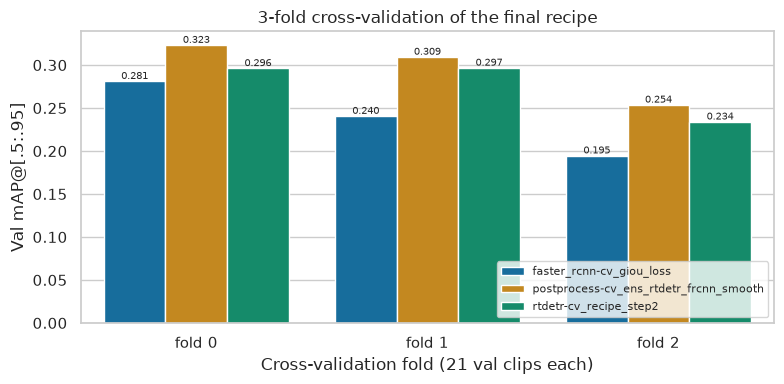

In [19]:
fig = plot_grouped_bars(
    cv.with_columns(pl.format("fold {}", "fold").alias("fold_name")).sort("fold", "model"),
    "fold_name", "map", "model",
    ("Cross-validation fold (21 val clips each)", "Val mAP@[.5:.95]", "3-fold cross-validation of the final recipe"),
    "{:.3f}",
)
fig.axes[0].legend(fontsize=8, loc="lower right")

- **The order of the three models is the same on every fold:** ensemble, RT-DETRv2, Faster R-CNN.

The fold ensembles include the temporal step, so their gain over RT-DETRv2 alone mixes fusion and I6. Both parts are separated here on each fold from the saved fold predictions, and the same two-member ensemble is scored on the adopted val split for comparison.

In [20]:
fold_rows = []
for k in range(3):
    fold_tables = load_annotations(DATA_ROOT, load_clip_split(DATA_CONFIG_PATH, f"fold_{k}"))
    fold_clips = {clip: "fold" for clip in fold_tables.images.filter(pl.col("split") == "val")["clip"].unique().to_list()}
    rtdetr, frcnn = f"rtdetr-cv_recipe_step2_fold{k}", f"faster_rcnn-cv_giou_loss_fold{k}"
    fold_rows.append(
        pl.concat(
            [
                score_members([rtdetr], {"RT-DETRv2": NO_TEMPORAL, "RT-DETRv2 + I6": {}}, fold_tables, fold_clips),
                score_members([rtdetr, frcnn], {"WBF": NO_TEMPORAL, "WBF + I6": {}}, fold_tables, fold_clips),
            ]
        ).select(pl.lit(f"fold {k}").alias("split"), "setting", "map")
    )
main_rows = pl.concat(
    [
        score_members([SINGLE], {"RT-DETRv2": NO_TEMPORAL, "RT-DETRv2 + I6": {}}, tables, clip_halves),
        score_members([SINGLE, "faster_rcnn-giou_loss"], {"WBF": NO_TEMPORAL, "WBF + I6": {}}, tables, clip_halves),
    ]
).select(pl.lit("adopted val").alias("split"), "setting", "map")
separation = (
    pl.concat([*fold_rows, main_rows])
    .pivot("setting", index="split", values="map")
    .with_columns(
        i6_on_single=pl.col("RT-DETRv2 + I6") - pl.col("RT-DETRv2"),
        fusion_without_i6=pl.col("WBF") - pl.col("RT-DETRv2"),
        i6_on_fusion=pl.col("WBF + I6") - pl.col("WBF"),
    )
)
separation.with_columns(pl.selectors.float().round(4))

split,RT-DETRv2,RT-DETRv2 + I6,WBF,WBF + I6,i6_on_single,fusion_without_i6,i6_on_fusion
str,f64,f64,f64,f64,f64,f64,f64
"""fold 0""",0.2961,0.3034,0.3098,0.3231,0.0072,0.0136,0.0134
"""fold 1""",0.2966,0.2992,0.292,0.3093,0.0026,-0.0046,0.0173
"""fold 2""",0.2339,0.2428,0.2345,0.2536,0.0088,0.0005,0.0191
"""adopted val""",0.3417,0.3478,0.3519,0.3632,0.0061,0.0102,0.0113


- **I6 gains on every fold,** on RT-DETRv2 alone (+0.0026 to +0.0088) and more on the fusion (+0.0134 to +0.0191).
- **Fusion without I6 is not consistent:** +0.0136 on fold 0, −0.0046 on fold 1, +0.0005 on fold 2, against +0.0102 on the adopted val. Most of the two-member ensemble gain on the folds comes from I6.

## 8. Validation and the public leaderboard

Every submission so far, with its val mAP and public LB score. The LB was used only as a final check of models chosen on val (data rule 4). The train and val models have no comparable val score: their val clips were in training.

In [21]:
submitted = (
    results.filter(pl.col("public_lb").is_not_null())
    .with_columns(is_val_comparable=~pl.col("experiment").str.contains("trainval"))
    .sort("public_lb", descending=True)
)
lb_table = submitted.select(
    "experiment", "is_val_comparable", pl.col("map", "map_max_width_1920", "public_lb").round(4),
    (pl.col("map") - pl.col("public_lb")).round(4).alias("val_minus_lb"),
)
display(lb_table)
lb_comparable = submitted.filter(pl.col("is_val_comparable"))
lb_comparable.select(
    pl.len().alias("submissions"),
    pl.corr("map", "public_lb", method="spearman").round(3).alias("spearman_val"),
    pl.corr("map_max_width_1920", "public_lb", method="spearman").round(3).alias("spearman_val_max_1920"),
    pl.corr("map", "public_lb").round(3).alias("pearson_val"),
)

experiment,is_val_comparable,map,map_max_width_1920,public_lb,val_minus_lb
str,bool,f64,f64,f64,f64
"""postprocess-ens_rtdetr4_frcnn2_yolo4_smooth""",true,0.3905,0.3632,0.3397,0.0508
"""postprocess-ens_rtdetr4_frcnn2_yolo3_smooth""",true,0.3887,0.362,0.3235,0.0652
"""postprocess-ens_yolo26m_p2_tiles_b16_tta""",true,0.3244,0.2914,0.3029,0.0215
"""postprocess-ens_rtdetr4_frcnn2_yolo2_smooth""",true,0.3859,0.3611,0.2981,0.0878
"""yolo-yolo26m_p2_tiles_b16""",true,0.3064,0.2751,0.2969,0.0095
"""postprocess-ens_trainval_rtdetr4_frcnn2_yolo2_smooth""",false,0.4934,0.4969,0.2884,0.205
"""postprocess-ens_recipe_frcnn_yolo_yolo1280_smooth""",true,0.3755,0.3559,0.2877,0.0878
"""rtdetr-recipe_step2_b16""",true,0.3398,0.3111,0.276,0.0638
"""rtdetr-infer_recipe_step2_det500""",true,0.3417,0.3191,0.2722,0.0695


submissions,spearman_val,spearman_val_max_1920,pearson_val
u32,f64,f64,f64
14,0.767,0.705,0.833


- **Every comparable submission scores lower on the LB than on val,** by 0.05 to 0.09 for most runs and 0.11 for RetinaNet.
- **YOLO26m-P2 is the exception:** 0.0095 for the single model and 0.0215 for its TTA. The ensembles with YOLO26m-P2 members also lose less (E 0.0652, F 0.0508, D 0.0878).
- **Val ranks the 14 comparable submissions like the LB with Spearman 0.767** (Pearson 0.833); the ≤ 1920 px subset ranks them worse (0.705).
- The train and val models score highest on val (they trained on it) and below their val-trained versions on the LB.

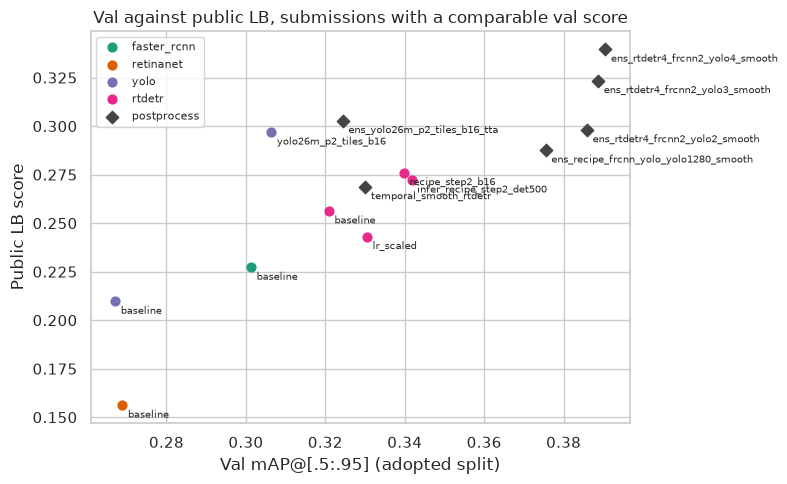

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
for family, color in FAMILY_COLORS.items():
    rows = lb_comparable.filter(pl.col("family") == family)
    ax.scatter(rows["map"], rows["public_lb"], color=color, s=40, label=family, marker="D" if family == "postprocess" else "o")
for row in lb_comparable.iter_rows(named=True):
    ax.annotate(row["experiment"].split("-", 1)[1], (row["map"], row["public_lb"]), xytext=(4, -9), textcoords="offset points", fontsize=7)
ax.set(xlabel="Val mAP@[.5:.95] (adopted split)", ylabel="Public LB score", title="Val against public LB, submissions with a comparable val score")
ax.legend(fontsize=8)
fig.tight_layout()

- **The YOLO26m-P2 points lie above the trend of all other runs,** and E and F rise more on the LB than on val against D.
- Hypothesis, not tested: training on tiles of frames resized to 1920 px matches the object scale of the test frames, which are all at most 1920 px wide.

Val frames come in three widths, while test has no frame above 1920 px and 16% half-resolution frames (test metadata only; nothing is fitted on test). Val mAP per width group of every comparable submission, and how well each group ranks the submissions like the LB:

In [23]:
test_images = load_test_images(DATA_ROOT)
width_group = (
    pl.when(pl.col("width") < 1000).then(pl.lit("< 1000 px"))
    .when(pl.col("width") < 1400).then(pl.lit("1344 to 1360 px"))
    .when(pl.col("width") <= 1920).then(pl.lit("1904 to 1920 px"))
    .otherwise(pl.lit("2688 px and above"))
)
pl.concat([val_images.select("split", "width"), test_images.select("split", "width")]).group_by(
    "split", width_group.alias("width_group")
).len("frames").with_columns(share=(pl.col("frames") / pl.col("frames").sum().over("split")).round(3)).pivot(
    "split", index="width_group", values=["frames", "share"]
).sort("width_group")

width_group,frames_val,frames_test,share_val,share_test
str,u32,u32,f64,f64
"""1344 to 1360 px""",827,1915,0.319,0.502
"""1904 to 1920 px""",1184,1296,0.457,0.34
"""2688 px and above""",582,null,0.224,null
"""< 1000 px""",null,600,null,0.157


- **Test has frame sizes that val lacks and the reverse:** 16% of test frames are below 1000 px wide, none in val; 22% of val frames are 2688 px and above, none in test.
- **The 1344 to 1360 px group** is half of test against a third of val.

In [24]:
val_width_groups = val_images.select("image_id", width_group.alias("group"))
width_rows = []
for experiment in lb_comparable["experiment"]:
    groups = evaluate_frame_groups(tables, "val", load_val_predictions(experiment), val_width_groups)
    width_rows.append(groups.select(pl.lit(experiment).alias("experiment"), "group", "map"))
by_width = (
    pl.concat(width_rows)
    .pivot("group", index="experiment", values="map")
    .join(lb_comparable.select("experiment", "map", "public_lb"), on="experiment")
    .sort("public_lb", descending=True)
)
display(by_width.with_columns(pl.selectors.float().round(4)))
width_columns = [c for c in by_width.columns if c.endswith(" px") or c.endswith("above")]
by_width.select(
    *(pl.corr(c, "public_lb", method="spearman").round(3).alias(c) for c in [*width_columns, "map"])
).with_columns(pl.lit("Spearman with LB").alias("statistic"))

experiment,1344 to 1360 px,2688 px and above,1904 to 1920 px,map,public_lb
str,f64,f64,f64,f64,f64
"""postprocess-ens_rtdetr4_frcnn2_yolo4_smooth""",0.358,0.4169,0.3412,0.3905,0.3397
"""postprocess-ens_rtdetr4_frcnn2_yolo3_smooth""",0.3561,0.4126,0.3413,0.3887,0.3235
"""postprocess-ens_yolo26m_p2_tiles_b16_tta""",0.2985,0.3623,0.2695,0.3244,0.3029
"""postprocess-ens_rtdetr4_frcnn2_yolo2_smooth""",0.3539,0.4063,0.3415,0.3859,0.2981
"""yolo-yolo26m_p2_tiles_b16""",0.2733,0.3357,0.2566,0.3064,0.2969
"""postprocess-ens_recipe_frcnn_yolo_yolo1280_smooth""",0.349,0.4035,0.339,0.3755,0.2877
"""rtdetr-recipe_step2_b16""",0.3022,0.3571,0.3011,0.3398,0.276
"""rtdetr-infer_recipe_step2_det500""",0.2991,0.3564,0.3104,0.3417,0.2722
"""postprocess-temporal_smooth_rtdetr""",0.2908,0.3388,0.2954,0.3301,0.2688


1344 to 1360 px,2688 px and above,1904 to 1920 px,map,statistic
f64,f64,f64,f64,str
0.842,0.934,0.534,0.767,"""Spearman with LB"""


- **The 2688 px and above group ranks the submissions most like the LB** (Spearman 0.934), then 1344 to 1360 px (0.842); 1904 to 1920 px ranks them least like it (0.534).
- **On 1904 to 1920 px frames, D, E, and F are equal** (0.3412 to 0.3415); F's val lead comes from the 1344 to 1360 px and 2688 px groups.
- No val group reproduces the large LB gain of the YOLO26m-P2 runs.

## 9. Final selection

The two final submissions, chosen on val before the LB score of F (`docs/pipeline.md` §13):

1. **F** (`ens_rtdetr4_frcnn2_yolo4_smooth`), the best validated pipeline: highest val mAP, and each step from D through E to F raised both val halves.
2. **D** (`ens_rtdetr4_frcnn2_yolo2_smooth`), the previous final, as the hedge: F without its two YOLO26m-P2 members, which come from a single late run trained on another machine. Each step from D to F is below the seed noise on val.

This replaces the earlier selection of D and D′ (§12.7 of `docs/pipeline.md`), which was fixed before F existed. D′ retrained the RT-DETRv2 and Faster R-CNN members of D on all 63 clips; no train and val version of the YOLO26m-P2 member was trained, so there is no D′ counterpart of F.

In [25]:
CANDIDATES = {FINAL: "F", PREVIOUS: "D", ENS_E: "E", FINAL_TRAINVAL: "D′", HEDGE: "B", SINGLE: "best single model on val", YOLO26: "YOLO26m-P2"}
display(
    submitted.filter(pl.col("experiment").is_in(list(CANDIDATES)))
    .with_columns(name=pl.col("experiment").replace_strict(CANDIDATES))
    .select("name", "experiment", "is_val_comparable", pl.col("map", "map_max_width_1920", "public_lb").round(4), pl.col("ms_per_image").round(1), pl.col("gpu_hours").round(2))
)
pl.DataFrame({"member of F": f_members}).with_columns(is_member_of_d=pl.col("member of F").is_in(d_members)).join(
    results.select(pl.col("experiment").alias("member of F"), "family", "machine", "map", "ap_small", pl.col("ms_per_image").round(1), pl.col("gpu_hours").round(2)),
    on="member of F",
    maintain_order="left",
)

name,experiment,is_val_comparable,map,map_max_width_1920,public_lb,ms_per_image,gpu_hours
str,str,bool,f64,f64,f64,f64,f64
"""F""","""postprocess-ens_rtdetr4_frcnn2_yolo4_smooth""",true,0.3905,0.3632,0.3397,498.2,10.95
"""E""","""postprocess-ens_rtdetr4_frcnn2_yolo3_smooth""",true,0.3887,0.362,0.3235,437.9,10.95
"""D""","""postprocess-ens_rtdetr4_frcnn2_yolo2_smooth""",true,0.3859,0.3611,0.2981,391.9,9.98
"""YOLO26m-P2""","""yolo-yolo26m_p2_tiles_b16""",true,0.3064,0.2751,0.2969,40.9,0.96
"""D′""","""postprocess-ens_trainval_rtdetr4_frcnn2_yolo2_smooth""",false,0.4934,0.4969,0.2884,397.8,5.02
"""B""","""postprocess-ens_recipe_frcnn_yolo_yolo1280_smooth""",true,0.3755,0.3559,0.2877,156.2,5.57
"""best single model on val""","""rtdetr-infer_recipe_step2_det500""",true,0.3417,0.3191,0.2722,53.9,1.58


member of F,is_member_of_d,family,machine,map,ap_small,ms_per_image,gpu_hours
str,bool,str,str,f64,f64,f64,f64
"""rtdetr-augment_recipe""",true,"""rtdetr""","""pc""",0.3373,0.1449,55.4,2.72
"""rtdetr-infer_recipe_hflip""",true,"""rtdetr""","""pc""",0.3382,0.1394,53.7,2.72
"""rtdetr-infer_recipe_step2_det500""",true,"""rtdetr""","""pc""",0.3417,0.1403,53.9,1.58
"""rtdetr-recipe_step2_repeat-s7""",true,"""rtdetr""","""pc""",0.3404,0.1356,53.1,1.54
"""faster_rcnn-giou_loss""",true,"""faster_rcnn""","""pc""",0.3066,0.1203,60.8,0.67
"""faster_rcnn-lr_cosine""",true,"""faster_rcnn""","""pc""",0.3062,0.1225,60.9,1.3
"""yolo-baseline""",true,"""yolo""","""pc""",0.2671,0.1119,13.7,1.12
"""yolo-imgsz_1280""",true,"""yolo""","""pc""",0.2498,0.1119,7.9,1.05
"""yolo-yolo26m_p2_tiles_b16""",false,"""yolo""","""colab""",0.3064,0.1051,40.9,0.96


- **F is the best submission on val (0.3905) and on the LB (0.3397),** 0.0416 above D on the LB.
- **F needs nine of its ten members from the PC** and one checkpoint from the G4; it costs 498 ms per image and 10.95 GPU hours of training, of which 0.96 on the G4.

## 10. Reproduction

Environment (Python 3.12, `uv`, exact versions in `uv.lock`; on Kaggle `requirements-kaggle.txt` over the preinstalled `torch`):

```bash
uv sync
cp .env.example .env   # set DATA_ROOT to the competition data
```

Each queue item trains (or predicts, or fuses), predicts all val frames and the test frames, evaluates with the shared evaluator, validates the CSV, and appends the `results.csv` row (`scripts/run_queue.sh`, `scripts/finish_run.sh`). Seeds: 42 everywhere except the seed 7 repeats (`*_repeat`, suffix `-s7`). GPU training is not bit-exact, so reproduced runs match within the seed noise rather than exactly.

**D** (members in the order of the config; an `infer` item needs its source run, trained earlier in the queue):

```bash
scripts/run_queue.sh \
    train:config/rtdetr/augment_recipe.toml \
    infer:config/rtdetr/infer_recipe_hflip.toml \
    train:config/rtdetr/recipe_step2.toml \
    infer:config/rtdetr/infer_recipe_step2_det500.toml \
    train:config/rtdetr/recipe_step2_repeat.toml \
    train:config/faster_rcnn/giou_loss.toml \
    train:config/faster_rcnn/lr_cosine.toml \
    train:config/yolo/baseline.toml \
    train:config/yolo/imgsz_1280.toml \
    post:config/postprocess/ens_rtdetr4_frcnn2_yolo2_smooth.toml
```

**F** (after D): YOLO26m-P2 trains on a GPU with about 50 GB of memory at batch 16 (a Colab G4 with 96 GB here; the 12 GB PC cannot hold it), then its run directory is copied to `runs/yolo-yolo26m_p2_tiles_b16/<timestamp>/` on the PC, which predicts, evaluates, and fuses:

```bash
# Colab G4, from the repository root with DATA_ROOT set
uv run python -m src.train --config config/yolo/yolo26m_p2_tiles_b16.toml
# PC
scripts/finish_run.sh runs/yolo-yolo26m_p2_tiles_b16/<timestamp>
scripts/run_queue.sh \
    infer:config/yolo/infer_yolo26m_p2_tiles_b16_size2304.toml \
    post:config/postprocess/ens_rtdetr4_frcnn2_yolo3_smooth.toml \
    post:config/postprocess/ens_rtdetr4_frcnn2_yolo4_smooth.toml
```

**D′** (after D, which provides the two YOLO members):

```bash
scripts/run_queue.sh \
    train:config/rtdetr/trainval_recipe_step5.toml \
    infer:config/rtdetr/infer_trainval_recipe_step5_hflip.toml \
    train:config/rtdetr/trainval_recipe_step2.toml \
    infer:config/rtdetr/infer_trainval_recipe_step2_det500.toml \
    train:config/rtdetr/trainval_recipe_step2_repeat.toml \
    train:config/faster_rcnn/trainval_giou_loss.toml \
    train:config/faster_rcnn/trainval_baseline_2ep.toml \
    post:config/postprocess/ens_trainval_rtdetr4_frcnn2_yolo2_smooth.toml
```

**Cross-validation** (section 7), for k in 0, 1, 2:

```bash
scripts/run_queue.sh \
    train:config/rtdetr/cv_recipe_step2_fold<k>.toml \
    train:config/faster_rcnn/cv_giou_loss_fold<k>.toml \
    post:config/postprocess/cv_ens_rtdetr_frcnn_smooth_fold<k>.toml
```

**Submission:** check the CSV, then copy it to `submissions/` and upload:

```bash
uv run python -m src.submission.validate runs/<experiment>/<timestamp>/predictions.csv
scripts/finish_run.sh runs/<experiment>/<timestamp> --submit
```

The recorded runs of the final members (config, seed, commit, training budget):

In [26]:
reproduction_members = [*f_members, *[m for m in trainval_config["members"] if m not in f_members]]
pl.DataFrame({"experiment": reproduction_members}).join(
    results.select(
        "experiment", "config", "machine", "seed", pl.col("commit").str.slice(0, 7), "is_dirty", "frame_step", "epochs",
        "effective_batch_size", pl.col("gpu_hours").round(2),
    ),
    on="experiment",
    maintain_order="left",
)

experiment,config,machine,seed,commit,is_dirty,frame_step,epochs,effective_batch_size,gpu_hours
str,str,str,i64,str,bool,i64,i64,i64,f64
"""rtdetr-augment_recipe""","""config/rtdetr/augment_recipe.toml""","""pc""",42,"""58e6109""",false,5,7,4,2.72
"""rtdetr-infer_recipe_hflip""","""config/rtdetr/infer_recipe_hflip.toml""","""pc""",42,"""64b4ba9""",false,5,7,4,2.72
"""rtdetr-infer_recipe_step2_det500""","""config/rtdetr/infer_recipe_step2_det500.toml""","""pc""",42,"""d99d0c6""",false,2,3,4,1.58
"""rtdetr-recipe_step2_repeat-s7""","""config/rtdetr/recipe_step2_repeat.toml""","""pc""",7,"""7dd7237""",false,2,3,4,1.54
"""faster_rcnn-giou_loss""","""config/faster_rcnn/giou_loss.toml""","""pc""",42,"""31279d7""",false,5,5,4,0.67
"""faster_rcnn-lr_cosine""","""config/faster_rcnn/lr_cosine.toml""","""pc""",42,"""31279d7""",false,5,10,4,1.3
"""yolo-baseline""","""config/yolo/baseline.toml""","""pc""",42,"""8d7cadd""",false,5,20,64,1.12
"""yolo-imgsz_1280""","""config/yolo/imgsz_1280.toml""","""pc""",42,"""0d30121""",false,5,20,64,1.05
"""yolo-yolo26m_p2_tiles_b16""","""config/yolo/yolo26m_p2_tiles_b16.toml""","""colab""",42,"""daffc33""",false,5,20,64,0.96


- **All members ran from a clean commit** (`is_dirty` false), with seed 42 except the seed 7 repeat.
- **The YOLO26m-P2 member** is the only one trained outside the PC; its 2304 px pass, evaluation, and fusion ran on the PC.

## 11. Conclusions

**Results**

- **Final pipeline.** F, the WBF of ten prediction sets from eight checkpoints of four detector families (four RT-DETRv2, two Faster R-CNN, two YOLO11s, two YOLO26m-P2), with temporal rescoring and box smoothing: 0.3905 val mAP, 0.3397 public LB, 498 ms per image (§2, §9).
- **Data.** The RT-DETRv2 augmentation recipe with frames at step 2 is the only data change above the seed noise (+0.0193, two seeds); masking ignored regions, low-resolution augmentation, and step 2 on YOLO26m-P2 do not gain (§3, §5.1).
- **Inference.** Only the YOLO26m-P2 TTA (+0.018, above the noise) and the temporal step (+0.009, on both halves and on the LB) gain consistently; larger inference sizes trade mAP for AP_small (§4).
- **Modelling.** The ensemble is the largest effect (+0.039 over the single model), with RT-DETRv2 its main family (−0.019 without it); YOLO26m-P2 is the largest single training gain (+0.039 over YOLO11s) (§5, §6).
- **Validation.** Val ranks the submissions like the LB with Spearman 0.767; the YOLO26m-P2 runs lose far less from val to LB than all others (0.010 against 0.05 to 0.09) (§8).
- **Cross-validation.** The two-member ensemble beats RT-DETRv2 on all three folds; the fold spread (std 0.036) is as large as the largest effects measured on the adopted split (§7).

**Hypotheses, not tested**

- YOLO26m-P2 transfers to test better because its tiles keep objects at the scale of test frames; checking it needs a full-frame YOLO26m without tiles.
- The gains of E and F on the LB (+0.025, +0.016) are larger than their val gains (+0.003, +0.002) because the test frame sizes differ from val (§8); a second YOLO26m-P2 seed would show how much of it is one lucky run.
- Training on all 63 clips lowered the LB for the two models where it was tried (§8); one seed per model leaves this unresolved.